# Heston: what each parameter does to the smile

Checks on `pricing.heston`:

1. **Smile vs. parameters**: implied volatility (Black-Scholes inversion of the Heston price) as one parameter moves at a time: $\rho$, $\xi$, $\kappa$, $v_0$.
2. **Fourier vs. Monte Carlo**: the Fourier price is the reference; the Euler full-truncation MC is biased and the bias depends on the number of time steps, not only on the number of paths.
3. **Feller condition**: what happens to the variance process when $2\kappa\theta < \xi^2$, and whether the price notices.

## The model: stochastic volatility

In Black-Scholes the volatility is a constant. Heston makes the *variance* $v_t$ a random process that mean-reverts, and correlates it with the stock:

$$dS_t = (r-q)\,S_t\,dt + \sqrt{v_t}\,S_t\,dW^{(1)}_t, \qquad dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW^{(2)}_t, \qquad d\langle W^{(1)}, W^{(2)}\rangle_t = \rho\,dt$$

| Parameter | Base value | Meaning | Effect on the smile |
|---|---|---|---|
| `v0` ($v_0$) | 0.04 | Initial variance. Today's vol is $\sqrt{v_0}$ = 20%. | Moves the whole smile up or down, mostly at short maturities. |
| `theta` ($\theta$) | 0.04 | Long-run variance: the level $v_t$ is pulled towards. | Sets the level of long maturities. If $v_0 < \theta$ the term structure of vol slopes up, if $v_0 > \theta$ it slopes down. |
| `kappa` ($\kappa$) | 2.0 | Speed of mean reversion. The half-life of a variance shock is $\ln 2 / \kappa$ (about 0.35 years here). | High $\kappa$ makes variance forget shocks quickly, so the smile flattens at long maturities. |
| `xi` ($\xi$) | 0.5 | Volatility of variance ("vol of vol"). | Curvature of the smile: more $\xi$ gives fatter tails and more expensive wings. With $\xi \to 0$ the model collapses to Black-Scholes. |
| `rho` ($\rho$) | -0.7 | Correlation between stock and variance shocks. | Skew. $\rho < 0$ (stock falls, vol rises) gives the usual equity skew with expensive low strikes. |

The Feller condition $2\kappa\theta \ge \xi^2$ guarantees $v_t$ never reaches zero. With the base values $2\kappa\theta = 0.16 < \xi^2 = 0.25$, so it does not hold. Section 3 looks at what that changes.


In [44]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricing.heston import HestonParams, heston_mc_price, heston_price
from pricing.implied_vol import implied_volatility

In [45]:
# Market parameters (same as previous notebooks, for comparability)
S0 = 100.0
T = 1.0
r = 0.05
q = 0.02

# Base Heston parameters. v0 = theta = 0.04 -> 20% vol, flat term structure of variance.
base = dict(v0=0.04, kappa=2.0, theta=0.04, xi=0.5, rho=-0.7)
strikes = np.linspace(70, 140, 25)


def heston_smile(**overrides):
    # Implied vol of OTM options (puts below the forward, calls above), which is the numerically stable choice.
    p = HestonParams(**{**base, **overrides})
    fwd = S0 * np.exp((r - q) * T)
    vols = []
    for K in strikes:
        opt = "put" if K < fwd else "call"
        vols.append(implied_volatility(heston_price(S0, K, T, r, p, opt, q), S0, K, T, r, opt, q))
    return np.array(vols)


print(f"Feller 2*kappa*theta = {2*base['kappa']*base['theta']:.3f}  vs  xi^2 = {base['xi']**2:.3f}")

Feller 2*kappa*theta = 0.160  vs  xi^2 = 0.250


**Reading the Feller line:** $2\kappa\theta = 0.16 < \xi^2 = 0.25$, so the base set **violates** the Feller condition (the ratio $2\kappa\theta/\xi^2$ is 0.64, and it would need to be at least 1). In theory this means the variance process can reach zero, where it is pushed back up instead of staying negative. It is a mild violation and it is on purpose: equity smiles need a large $\xi$ and a negative $\rho$, so calibrated parameters often break the condition too.

What it does and does not affect: the Fourier price is exact either way, so all the smiles below are fine. It is the Monte Carlo that suffers, because Euler steps can land at $v<0$ and the scheme relies on `max(v, 0)`. That is the bias seen in section 2, and section 3 measures it with a much stronger violation.

## 1. Smile vs. parameters

Each panel changes one parameter and keeps the others at the base values.

**Why only OTM options:** an ITM option is mostly intrinsic value, and only a small slice of its price depends on volatility. Inverting Black-Scholes there amplifies any numerical error in the price (the Fourier integral has some) into a large error in vol. An OTM option is pure time value, so its price is sensitive to vol and the inversion is stable. No information is lost: by put-call parity an ITM call and the OTM put at the same strike have the same implied vol, so the smile is the same. We use puts below the forward and calls above it.

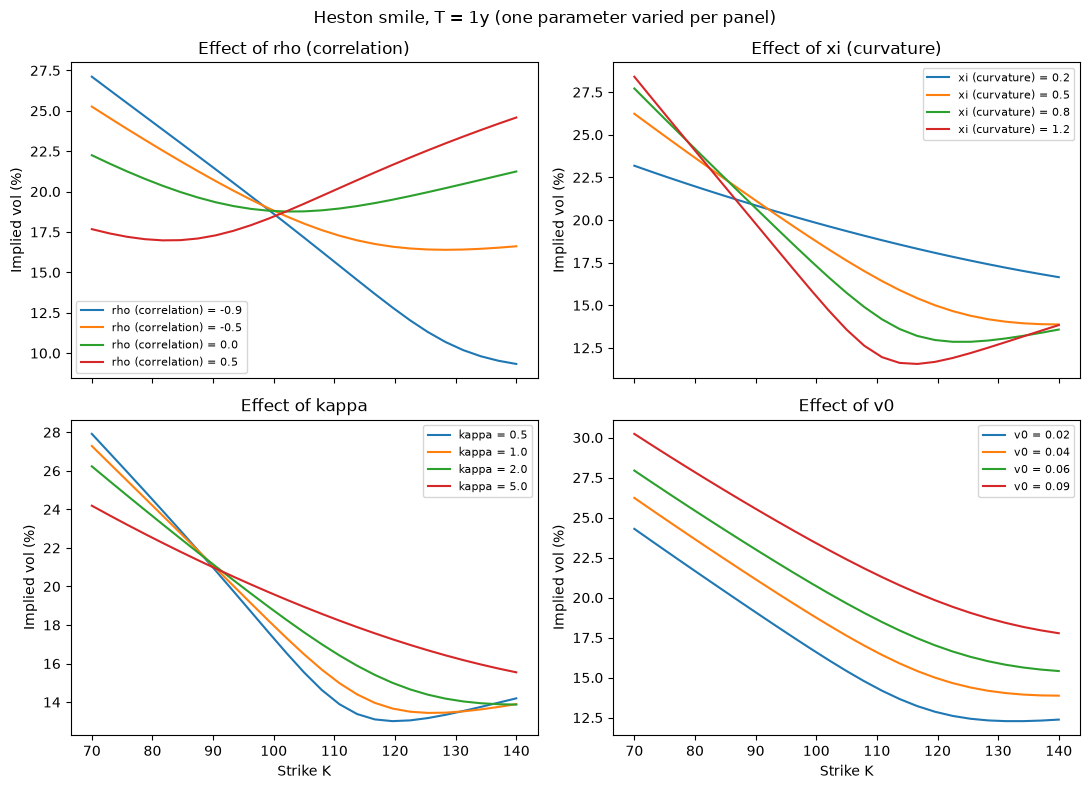

In [46]:
grids = {
    "rho (correlation)": [-0.9, -0.5, 0.0, 0.5],
    "xi (curvature)": [ 0.2, 0.5, 0.8, 1.2],
    "kappa": [0.5, 1.0, 2.0, 5.0],
    "v0": [0.02, 0.04, 0.06, 0.09],
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, (name, values) in zip(axes.ravel(), grids.items()):
    for v in values:
        ax.plot(strikes, 100 * heston_smile(**{name.split()[0]: v}), label=f"{name} = {v}")
    ax.set_title(f"Effect of {name}")
    ax.set_ylabel("Implied vol (%)")
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Strike K")
fig.suptitle("Heston smile, T = 1y (one parameter varied per panel)")
fig.tight_layout()
plt.show()

In [47]:
# Numbers behind the picture: ATM vol, 80/120 skew and curvature (butterfly) for each case.
rows = []
for name, values in grids.items():  # name may carry a label, e.g. "xi (curvature)"; the parameter is its first word
    for v in values:
        s = heston_smile(**{name.split()[0]: v})
        atm = s[len(s) // 2]
        rows.append({"param": name, "value": v, "ATM": atm, "skew (K=80 - K=120)": s[np.argmin(abs(strikes-80))] - s[np.argmin(abs(strikes-120))],
                     "wings avg - ATM": 0.5*(s[0]+s[-1]) - atm})
pd.DataFrame(rows).round(4)

,param,value,ATM,skew (K=80 - K=120),wings avg - ATM
0,rho (correlation),-0.90,0.1715,0.1183,0.0107
1,rho (correlation),-0.50,0.1802,0.0661,0.0292
2,rho (correlation),0.00,0.1878,0.0129,0.0297
3,rho (correlation),0.50,0.1925,-0.0460,0.0188
4,xi (curvature),0.20,0.1935,0.0405,0.0057
5,xi (curvature),0.50,0.1762,0.0897,0.0243
6,xi (curvature),0.80,0.1573,0.1166,0.0492
7,xi (curvature),1.20,0.1357,0.1293,0.0755
8,kappa,0.50,0.1554,0.1193,0.0551
9,kappa,1.00,0.1648,0.1092,0.0411


**What the table shows**

- $\rho$ is the skew knob: the 80-vs-120 vol gap goes from 0.116 at $\rho=-0.9$ to $-0.047$ at $\rho=+0.5$, and is about zero at $\rho=0$. Negative correlation (spot down, vol up) makes low strikes expensive, which is the equity-like shape.
- $\xi$ (vol of vol) is the curvature knob: the "wings average minus ATM" goes from 0.004 at $\xi=0.2$ to 0.050 at $\xi=1.2$. It also adds skew when $\rho<0$. Notice that ATM vol *falls* as $\xi$ grows (0.198 to 0.155) while $v_0=\theta$ stays fixed: more vol of vol puts more variance in the tails of $S_T$ but the ATM price barely moves, so the ATM implied vol drops.
- $\kappa$ controls how fast variance mean-reverts. At $T=1$ a low $\kappa$ keeps the skew steeper (0.115 at $\kappa=0.5$ vs 0.053 at $\kappa=5$), because fast mean reversion averages the vol shocks out before maturity and the smile flattens.
- $v_0$ mostly shifts the level (ATM from 0.166 to 0.234) and leaves the shape almost unchanged (skew 0.088 to 0.081).

Positive skew represents low puts have more volatility than high calls, like equity

Rho impacts on skew
Xi curvature
Kappa slope at 1 year
v0 does not alter smile but moves high or low . It is initial volatility


## Does a combination of parameters always give a "smile"?

No. The same five parameters can produce very different shapes, and each shape matches a kind of market you see every day:

| Shape | Typical market | Heston recipe |
|---|---|---|
| **Skew / smirk** (low strikes expensive) | Equity indices (S&P 500, Euro Stoxx): people pay for crash protection | $\rho < 0$ |
| **Symmetric smile** (both wings expensive) | FX pairs such as EUR/USD: the risk is two-sided | $\rho \approx 0$, $\xi$ large enough |
| **Reverse skew** (high strikes expensive) | Commodities and some single stocks: the fear is a spike *up* | $\rho > 0$ |
| **Flat** | Black-Scholes world | $\xi \approx 0$ |

First the four recipes, then a real example: the SPY smile from the options chain downloaded with `vol-surface-risk` (falls back to the committed synthetic sample if the live snapshot is not on disk, since it is git-ignored).

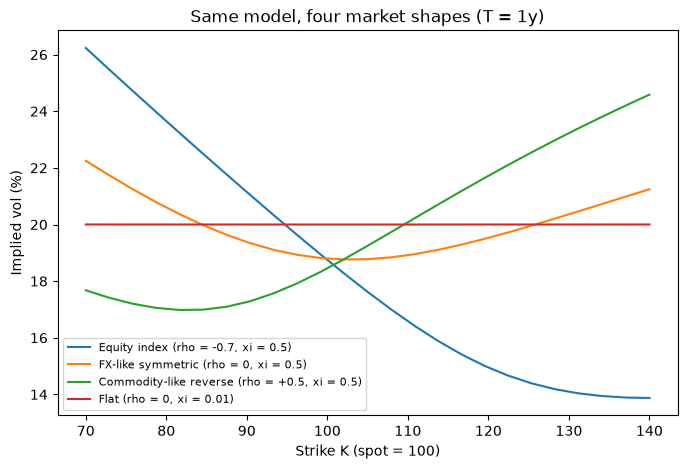

In [48]:
archetypes = {
    "Equity index (rho = -0.7, xi = 0.5)": dict(rho=-0.7, xi=0.5),
    "FX-like symmetric (rho = 0, xi = 0.5)": dict(rho=0.0, xi=0.5),
    "Commodity-like reverse (rho = +0.5, xi = 0.5)": dict(rho=0.5, xi=0.5),
    "Flat (rho = 0, xi = 0.01)": dict(rho=0.0, xi=0.01),
}
fig, ax = plt.subplots(figsize=(8, 5))
for label, ov in archetypes.items():
    ax.plot(strikes, 100 * heston_smile(**ov), label=label)
ax.set_xlabel("Strike K (spot = 100)")
ax.set_ylabel("Implied vol (%)")
ax.set_title("Same model, four market shapes (T = 1y)")
ax.legend(fontsize=8)
plt.show()

From spy options, calculate implied vol and plot market smile.

Get mid point from bid ask price
Get forward by F = K + (C - P)·e^{rT}
Get OTM, so puts below forward and calls up fwd
Invert Black-Scholes -> search sigma that makes Black-Scholes price equals mid opcion price

Higher stike lower volatility, more otm.
Wider spread is less precise and weigth in the fit is less acurate

       expiry         T  strike option_type  bid   ask    mid     forward  \
0  2026-10-30  0.019178   640.0         put  0.1  0.11  0.105  761.161638   
1  2026-10-30  0.019178   641.0         put  0.1  0.11  0.105  761.161638   
2  2026-10-30  0.019178   642.0         put  0.1  0.11  0.105  761.161638   
3  2026-10-30  0.019178   643.0         put  0.1  0.11  0.105  761.161638   
4  2026-10-30  0.019178   644.0         put  0.1  0.12  0.110  761.161638   

          k  volume  open_interest        iv         w        weight  
0 -0.173378   439.0           2596  0.505443  0.004899  3.416678e+08  
1 -0.171816   853.0           1922  0.501371  0.004821  3.518971e+08  
2 -0.170257    85.0           1225  0.497303  0.004743  3.625080e+08  
3 -0.168701    97.0           5221  0.493239  0.004666  3.735180e+08  
4 -0.167147   317.0           3866  0.491849  0.004639  1.016829e+08  


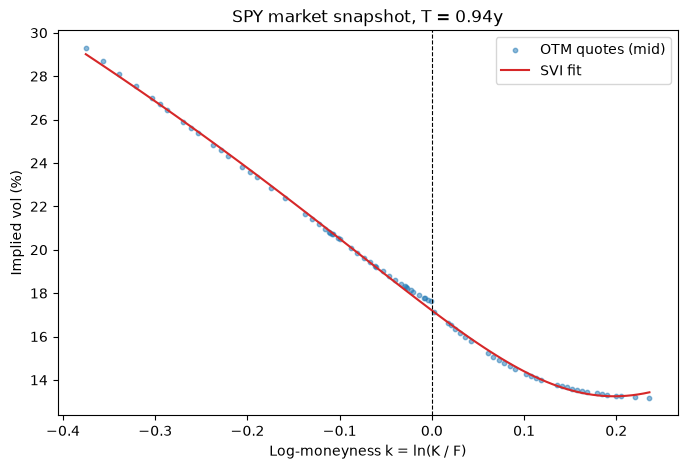

k = -0.2  (K/F = 0.82):  implied vol = 23.8%
k = +0.0  (K/F = 1.00):  implied vol = 17.2%
k = +0.1  (K/F = 1.11):  implied vol = 14.4%


In [49]:
from pathlib import Path
from volrisk.data import load_snapshot, prepare_chain
from volrisk.surface import build_surface, implied_vols_from_quotes

data_dir = Path("../vol-surface-risk/data")
live, sample = data_dir / "SPY_2026-10-23.csv", data_dir / "sample_SPY.csv"
path, label = (live, "SPY market snapshot") if live.exists() else (sample, "synthetic sample (not real data)")
prepared = prepare_chain(load_snapshot(path))

raw = implied_vols_from_quotes(prepared)
print(raw.head())
surface = build_surface(prepared)

T_real = float(surface.maturities[-1])                  # longest expiry in the chain
pts = raw[np.isclose(raw["T"], T_real)]
k_grid = np.linspace(pts["k"].min(), pts["k"].max(), 100)
fwd_real = surface.forward(T_real)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pts["k"], 100 * pts["iv"], s=10, alpha=0.5, label="OTM quotes (mid)")
ax.plot(k_grid, 100 * surface.vol(fwd_real * np.exp(k_grid), T_real), color="C3", label="SVI fit")
ax.axvline(0, color="k", linestyle="--", linewidth=0.8)
ax.set_xlabel("Log-moneyness k = ln(K / F)")
ax.set_ylabel("Implied vol (%)")
ax.set_title(f"{label}, T = {T_real:.2f}y")
ax.legend()
plt.show()

for kk in (-0.2, 0.0, 0.1):
    print(f"k = {kk:+.1f}  (K/F = {np.exp(kk):.2f}):  implied vol = {100 * surface.vol(fwd_real * np.exp(kk), T_real):.1f}%")

plot is ln(k/f) and not only stike because level is normalized for the active. This way we can compare higher or lower stikes for diff activos and even compare them. 

k is a metric to measure porcentual length between strike and fwd.

OJO: for diff maturities same k can be tricky. Sigma increases with square time

1 week:  sigma=2.35%.    with k=-0.17    move is 7 times normal -> 0.17/0.0235 = 7
1 year:  sigma=17%.      with k=-0.17    move is 1 times normal -> 0.17/0.17 = 1

**What it shows**

- Same model, four shapes. Vol at K = 80 / 100 / 120: equity-like 23.7 / 18.7 / 14.9 (a steep skew), FX-like 20.6 / 18.8 / 19.5 (a smile: both wings above the middle), commodity-like 17.0 / 18.5 / 21.7 (the skew flipped), and flat 20.0 everywhere. Only $\rho$ and $\xi$ changed.
- The real SPY curve is the first case. At the longest expiry the vol is 23.8% at $K = 0.82F$, 17.2% at the forward and 14.4% at $K = 1.11F$. Low strikes are about 9 vol points above the high ones, and there is no wing coming back up on the call side. It is a skew (a smirk), not a symmetric smile, which is what $\rho < 0$ gives. People pay for puts as crash insurance, so low-strike options carry more vol.
- This is also why the model is useful: calibrating Heston (or SVI, or SABR) to a real curve means finding the $\rho$, $\xi$, $v_0$... that reproduce that shape, which is what the next notebooks do.

### The implied volatility surface (interactive)

A smile is one maturity. Add maturity $T$ as a second axis and the smiles of all expiries stack into a surface $\sigma_{imp}(k, T)$. Drag to rotate, scroll to zoom, hover to read values.

One warning from the previous section: the same $k$ means different things at different maturities, because the typical move $\sigma\sqrt{T}$ grows with $T$. So each surface is drawn twice:

- **Left, in log-moneyness** $k = \ln(K/F)$. Easy to read in terms of strikes, but a fixed $k$ is a huge move at 7 days and a small one at 1 year.
- **Right, in standardised moneyness** $z = k / (\sigma_{ATM}\sqrt{T})$, i.e. "how many typical moves away from the forward". Here the same $z$ means about the same thing at every maturity.

First the market (SPY chain, SVI fit per expiry, black dots are the quotes; blank where an expiry has no quotes), then the Heston model with the base parameters.

In [50]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def surface_figure(vol_fn, T_axis, k_axis, z_axis, quotes=None, title=""):
    # vol_fn(k, T) -> implied vol in %, nan where it is not defined.
    # Surfaces are built on a regular grid of k (left) and of z = k / (sigma_ATM sqrt(T)) (right).
    atm = np.array([vol_fn(0.0, T) / 100 for T in T_axis])
    sd = atm * np.sqrt(T_axis)                          # typical move for each maturity
    V_k = np.array([[vol_fn(k, T) for k in k_axis] for T in T_axis])
    V_z = np.array([[vol_fn(z * s, T) for z in z_axis] for T, s in zip(T_axis, sd)])
    K_grid, T_k = np.meshgrid(k_axis, T_axis)
    Z_grid, T_z = np.meshgrid(z_axis, T_axis)

    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "surface"}] * 2],
                        subplot_titles=("x = log-moneyness k", "x = standardised moneyness z = k / (ATM vol * sqrt T)"))
    for col, (X, Y, Z) in enumerate([(K_grid, T_k, V_k), (Z_grid, T_z, V_z)], start=1):
        fig.add_trace(go.Surface(x=X, y=Y, z=Z, colorscale="Viridis", showscale=False, opacity=0.9,
                                 hovertemplate="x=%{x:.2f}<br>T=%{y:.2f}y<br>vol=%{z:.1f}%<extra></extra>"), row=1, col=col)
    if quotes is not None:
        sd_map = dict(zip(np.round(T_axis, 6), sd))
        q_sd = quotes["T"].round(6).map(sd_map)
        for col, x in enumerate([quotes["k"], quotes["k"] / q_sd], start=1):
            lo, hi = (k_axis.min(), k_axis.max()) if col == 1 else (z_axis.min(), z_axis.max())
            m = x.between(lo, hi)
            fig.add_trace(go.Scatter3d(x=x[m], y=quotes.loc[m, "T"], z=100 * quotes.loc[m, "iv"], mode="markers",
                                       marker=dict(size=2, color="black"), hoverinfo="skip", showlegend=False), row=1, col=col)
    scene = dict(yaxis_title="Maturity T (years)", zaxis_title="Implied vol (%)", camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9)))
    fig.update_layout(scene=dict(xaxis_title="k", **scene), scene2=dict(xaxis_title="z", **scene),
                      title=title, height=520, margin=dict(l=0, r=0, t=60, b=0))
    return fig


# Market: SVI surface of the SPY chain, blank outside the quoted range of each expiry.
T_mkt = np.array(surface.maturities)
k_rng = {round(float(T), 6): (g["k"].min(), g["k"].max()) for T, g in raw.groupby("T")}


def market_vol(k, T):
    # k and T come as floats; look the expiry up by T, return nan if k has no quotes there.
    T_key = round(float(T_mkt[np.argmin(abs(T_mkt - T))]), 6)
    lo, hi = k_rng[T_key]
    if not lo <= k <= hi:
        return np.nan
    return 100 * float(surface.vol(surface.forward(T) * np.exp(k), T))


surface_figure(market_vol, T_mkt, np.linspace(-0.45, 0.2, 50), np.linspace(-3, 2, 50), quotes=raw,
               title=f"Implied volatility surface: {label}").show()

In [51]:
# Heston model surface with the base parameters.
p_base = HestonParams(**base)


def heston_vol(k, T):
    F = S0 * np.exp((r - q) * T)
    K = F * np.exp(k)
    opt = "put" if k < 0 else "call"
    try:
        return 100 * implied_volatility(heston_price(S0, K, T, r, p_base, opt, q), S0, K, T, r, opt, q)
    except ValueError:
        return np.nan   # option worth less than the numerical precision of the price


T_heston = np.array([0.1, 0.25, 0.5, 1.0, 1.5, 2.0])
surface_figure(heston_vol, T_heston, np.linspace(-0.45, 0.2, 50), np.linspace(-3, 2, 50),
               title="Heston implied volatility surface (base parameters)").show()

# The skew at each maturity, in both coordinates (vol points above the ATM vol).
rows = []
for T in T_heston:
    atm_v = heston_vol(0.0, T)
    sd_T = atm_v / 100 * np.sqrt(T)
    rows.append({"T": T, "ATM vol (%)": atm_v, "skew at k = -0.1": heston_vol(-0.1, T) - atm_v,
                 "skew at z = -1": heston_vol(-sd_T, T) - atm_v})
pd.DataFrame(rows).round(2)

,T,ATM vol (%),skew at k = -0.1,skew at z = -1
0,0.10,19.50,3.87,2.48
1,0.25,18.92,3.64,3.46
2,0.50,18.38,3.14,4.01
3,1.00,18.05,2.30,4.08
4,1.50,18.05,1.79,3.91
5,2.00,18.11,1.47,3.72


In [52]:
# Same table for the market: skew at k = -0.1 and at z = -1, per expiry.
rows = []
for T in T_mkt:
    atm_v = market_vol(0.0, T)
    sd_T = atm_v / 100 * np.sqrt(T)
    rows.append({"T": T, "ATM vol (%)": atm_v, "skew at k = -0.1": market_vol(-0.1, T) - atm_v,
                 "skew at z = -1": market_vol(-sd_T, T) - atm_v})
pd.DataFrame(rows).round(2)

,T,ATM vol (%),skew at k = -0.1,skew at z = -1
0,0.02,16.00,17.97,3.00
1,0.04,15.58,14.22,3.75
2,0.06,15.36,12.45,4.13
3,0.10,14.49,9.72,4.23
4,0.19,15.03,7.55,4.77
5,0.33,15.43,5.66,4.94
6,0.44,15.79,4.83,5.05
7,0.94,17.20,3.30,5.49


**Reading the surfaces (and a correction to my first reading)**

- In log-moneyness the skew looks like it **flattens** with maturity: for SPY, the gap between $k=-0.1$ and the forward falls from 18.0 vol points at 7 days to 3.3 at 0.94 years (Heston: 3.9 to 1.5 between $T=0.1$ and 2). That is the left panel, and it is mostly an effect of the axis: $k=-0.1$ is about 4 typical moves away at 7 days and about 0.6 at one year.
- Measured in typical moves ($z=-1$) the skew does **not** flatten: for SPY it goes from 3.0 to 5.5 vol points with maturity, and in Heston it stays between 2.5 and 4.1. Once the distance is standardised the smiles of different expiries line up much better (right panel). The decay in $k$ is roughly the $1/\sqrt{T}$ behaviour of the ATM skew seen in real markets.
- So the sharp ridge at the left edge in the $k$ panel is largely a coordinate effect, not extra fear of crashes at short maturities. Reading a surface in $k$ without remembering that $k$ is not comparable across $T$ is the mistake to avoid.
- This surface is the object that `vol-surface-risk` builds, checks for butterfly and calendar arbitrage, and uses to price and risk any option, quoted or not.

## 2. Fourier vs. Monte Carlo, and the time-step bias

The Fourier price is accurate to many digits, so it acts as the reference. In MC there are two independent error sources: sampling noise ($\propto 1/\sqrt{N_{paths}}$) and discretisation bias (depends on `n_steps`). The standard error printed by `mc_price` only measures the first one.

In [53]:
p = HestonParams(**base)
K = 100.0
exact = heston_price(S0, K, T, r, p, "call", q)
print(f"Fourier price: {exact:.6f}")

rows = []
for n_steps in [1, 2, 5, 10, 25, 50, 100, 250]:
    res = heston_mc_price(S0, K, T, r, p, "call", q, n_paths=400_000, n_steps=n_steps, seed=1)
    rows.append({"n_steps": n_steps, "MC price": res.price, "SE": res.std_error, "bias (MC - Fourier)": res.price - exact,
                 "bias / SE": (res.price - exact) / res.std_error})
df_steps = pd.DataFrame(rows)
df_steps.round(5)

Fourier price: 8.439162


,n_steps,MC price,SE,bias (MC - Fourier),bias / SE
0,1,8.84587,0.02099,0.40670,19.37188
1,2,9.15203,0.01924,0.71286,37.04289
2,5,8.71401,0.01658,0.27484,16.57950
3,10,8.54844,0.01591,0.10927,6.86911
4,25,8.49330,0.01565,0.05414,3.45991
5,50,8.47405,0.01558,0.03489,2.23899
6,100,8.46476,0.01553,0.02560,1.64848
7,250,8.47030,0.01555,0.03114,2.00292


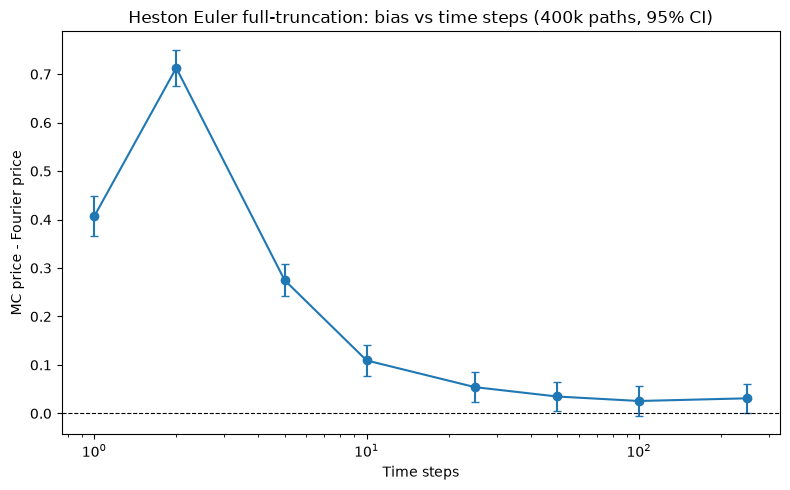

In [54]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(df_steps["n_steps"], df_steps["MC price"] - exact, yerr=1.96 * df_steps["SE"], fmt="o-", capsize=3)
ax.axhline(0, color="k", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Time steps")
ax.set_ylabel("MC price - Fourier price")
ax.set_title("Heston Euler full-truncation: bias vs time steps (400k paths, 95% CI)")
fig.tight_layout()
plt.show()

**What the bias looks like**

With 1 to 5 steps the MC price is wrong by 0.3 to 0.75 (more than 15 standard errors), and it is not even monotone in `n_steps`: one very coarse step is not a "smaller version" of the right answer. From 10 steps on it shrinks quickly (0.11 at 10, 0.057 at 25, 0.037 at 50). At 100 and 250 steps the difference to the Fourier price is about 0.03, roughly 2 SE. With 400k paths I can no longer separate residual bias from noise, and the standard error alone would say the estimate is fine. That is the point: the CI printed by `heston_mc_price` ignores discretisation bias.

## 3. Feller condition

If $2\kappa\theta \ge \xi^2$ the variance process never touches zero. Otherwise it hits zero and reflects; in simulation that means many Euler steps land at negative $v$ and the truncation `max(v, 0)` is actually being used. Below, a parameter set that violates Feller (strongly) vs. one that satisfies it.

In [55]:
satisfied = HestonParams(v0=0.04, kappa=3.0, theta=0.04, xi=0.3, rho=-0.7)
violated = HestonParams(v0=0.04, kappa=1.0, theta=0.04, xi=1.0, rho=-0.7)
for label, pp in [("Feller satisfied", satisfied), ("Feller violated", violated)]:
    print(f"{label}: 2*kappa*theta = {2*pp.kappa*pp.theta:.3f}, xi^2 = {pp.xi**2:.3f}, flag = {pp.feller_satisfied}")

# Fraction of simulated variance values that go negative before truncation (same Euler scheme as heston_mc_price).
def negative_variance_fraction(pp, n_paths=20_000, n_steps=100, seed=0):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    v = np.full(n_paths, pp.v0)
    neg = 0
    total = 0
    for _ in range(n_steps):
        z2 = rng.standard_normal(n_paths)
        vp = np.maximum(v, 0.0)
        v = v + pp.kappa * (pp.theta - vp) * dt + pp.xi * np.sqrt(vp * dt) * z2
        neg += (v < 0).sum()
        total += v.size
    return neg / total

for label, pp in [("Feller satisfied", satisfied), ("Feller violated", violated)]:
    print(f"{label}: fraction of steps with v < 0 = {negative_variance_fraction(pp):.4f}")

Feller satisfied: 2*kappa*theta = 0.240, xi^2 = 0.090, flag = True
Feller violated: 2*kappa*theta = 0.080, xi^2 = 1.000, flag = False
Feller satisfied: fraction of steps with v < 0 = 0.0001
Feller violated: fraction of steps with v < 0 = 0.4536


In [56]:
rows = []
for label, pp in [("Feller satisfied", satisfied), ("Feller violated", violated)]:
    for K in (80.0, 100.0, 120.0):
        exact_k = heston_price(S0, K, T, r, pp, "call", q)
        for n_steps in (10, 100, 400):
            res = heston_mc_price(S0, K, T, r, pp, "call", q, n_paths=200_000, n_steps=n_steps, seed=3)
            rows.append({"case": label, "K": K, "n_steps": n_steps, "Fourier": exact_k, "MC": res.price, "SE": res.std_error,
                         "bias/SE": (res.price - exact_k) / res.std_error})
pd.DataFrame(rows).round(4)

,case,K,n_steps,Fourier,MC,SE,bias/SE
0,Feller satisfied,80.0,10,22.9395,22.8624,0.0365,-2.1121
1,Feller satisfied,80.0,100,22.9395,22.9365,0.0366,-0.0816
2,Feller satisfied,80.0,400,22.9395,22.9453,0.0366,0.1572
3,Feller satisfied,100.0,10,8.7970,8.7368,0.0254,-2.3728
4,Feller satisfied,100.0,100,8.7970,8.7993,0.0255,0.0907
5,Feller satisfied,100.0,400,8.7970,8.8098,0.0254,0.5020
6,Feller satisfied,120.0,10,1.7742,1.7547,0.0113,-1.7296
7,Feller satisfied,120.0,100,1.7742,1.7833,0.0114,0.7976
8,Feller satisfied,120.0,400,1.7742,1.7750,0.0112,0.0722
9,Feller violated,80.0,10,23.3108,23.7768,0.0303,15.3736


**What Feller does here**

- Satisfied ($2\kappa\theta=0.24 \ge \xi^2=0.09$): only 0.01% of Euler steps give a negative variance, and the MC is within about 2.4 SE of Fourier already with 10 steps and within 1 SE at 100.
- Violated ($2\kappa\theta=0.08 < \xi^2=1.0$): 46% of the steps produce $v<0$ before truncation, so the scheme is leaning on `max(v, 0)` all the time. With 10 steps the ATM price is off by 53 SE (8.40 vs 7.26) and the OTM call at $K=120$ is almost double (1.03 vs 0.54). With 100 steps it is still off by 4 to 5 SE; with 400 steps it is back to within about 1.5 SE.

The Fourier price does not care about Feller (the characteristic function is exact either way). So the condition is a simulation problem, not a pricing-model problem, and that is why calibrated Heston parameters on real equity smiles often violate it: the market wants a large $\xi$ and a strongly negative $\rho$. Better schemes for that regime (Andersen's QE, exact non-central chi-square sampling) are not implemented here.